# Moment-based validation of `FlexionTransform`

This notebook was written with help from Claude Code (reviewed and guided by Dani Leonard..)

We render a circular exponential galaxy through BATSim's `FlexionTransform` (no shear, no
convergence, no PSF) and compare two simple pixel-sum moments against closed-form predictions:

* **First flexion $F$** moves the **centroid**: $\Delta\bar x = \tfrac32\,F\,\langle r^2\rangle$.
* **Second flexion $G$** excites the **trefoil moment**:
  $T \equiv \sum\cos 3\theta\, I = \tfrac{3\pi}{4}\,G\int_0^\infty r^2 I_0(r)\,dr$.

No shear or flexion estimator is needed. The measurements are plain numpy reductions over the
rendered image. This notebook plays the same role for flexion that
`effective_shear_DL.ipynb` plays for `IaTransform`. The design follows
`flexion_validation_test_notes.md`.

In [1]:
import galsim
import numpy as np
import matplotlib.pylab as plt
from scipy import integrate

import batsim

# Derivation

**Source profile.** The test galaxy is a circular exponential profile,

$$ I_0(r) = \frac{F_{\rm tot}}{2\pi r_s^2}\,e^{-r/r_s}, $$

where $r_s$ is the **scale radius**, the radius over which the surface brightness falls by a
factor of $e$. It is related to the half-light radius by $r_{\rm hlr}\simeq1.678\,r_s$, so
$r_{\rm hlr}=0.5''$ gives $r_s\simeq0.298''$. The code takes $r_s$ from GalSim's
`Exponential.scale_radius`. The general results below hold for any circular $I_0(r)$. $r_s$
only enters when we evaluate them for this profile.

**Coordinate maps.** `FlexionTransform` is a pull map from image-plane coordinates
$(x', y')$ to source-plane coordinates $(x, y)$:
$x_i = A_{ij}x'_j + \tfrac12 D_{ijk}x'_jx'_k$. We set $A=\mathbb 1$. Expanding
$D_{ij1}$, $D_{ij2}$ from `src/batsim/transforms.py` gives

$$
\begin{aligned}
x &= x' - \tfrac14\Big[(3F_1+G_1)\,x'^2 + 2(F_2+G_2)\,x'y' + (F_1-G_1)\,y'^2\Big],\\
y &= y' - \tfrac14\Big[(F_2+G_2)\,x'^2 + 2(F_1-G_1)\,x'y' + (3F_2-G_2)\,y'^2\Big].
\end{aligned}
$$

For pure $F_1=F$ this reduces to $x = x' - \tfrac34Fx'^2 - \tfrac14Fy'^2,\; y = y' - \tfrac12Fx'y'$.
For pure $G_1=G$ it reduces to $x = x' + \tfrac G4(y'^2-x'^2),\; y = y'+\tfrac G2x'y'$.

**Linear response.** Drop the primes and write $\delta\mathbf x = (x - x', y - y')$ for the
displacement. For a circular source $I_0(r)$, $\nabla I_0 = I_0'(r)\,(x, y)/r$, and to first order
$\delta I = \nabla I_0\cdot\delta\mathbf x$. Using $x = r\cos\theta$, $y = r\sin\theta$:

* $F_1$: $\delta\mathbf x = -\tfrac{F_1}{4}\,(3x^2+y^2,\ 2xy)$, so
  $\delta I = -\tfrac{F_1}{4}\,\tfrac{I_0'}{r}\,3x(x^2+y^2) = -\tfrac{3F_1}{4}\,r^2I_0'\cos\theta$.
* $F_2$: $\delta\mathbf x = -\tfrac{F_2}{4}\,(2xy,\ x^2+3y^2)$, so
  $\delta I = -\tfrac{3F_2}{4}\,r^2I_0'\sin\theta$.
* $G_1$: $\delta\mathbf x = \tfrac{G_1}{4}\,(y^2-x^2,\ 2xy)$, so
  $\delta I = -\tfrac{G_1}{4}\,\tfrac{I_0'}{r}\,(x^3-3xy^2) = -\tfrac{G_1}{4}\,r^2I_0'\cos3\theta$.
* $G_2$: $\delta\mathbf x = -\tfrac{G_2}{4}\,(2xy,\ x^2-y^2)$, so
  $\delta I = -\tfrac{G_2}{4}\,r^2I_0'\sin3\theta$.

First flexion produces only an $m=1$ (dipole) azimuthal pattern, which the centroid probes.
Second flexion produces only an $m=3$ (trefoil) pattern, which the $\cos3\theta$ moment probes.

**First flexion: centroid.** Take pure $F_1=F$ and change variables to the source plane. The
Jacobian of the pull map is $\det J = 1-2Fx+O(F^2)$, so $d^2x' \simeq (1+2Fx)\,d^2x$. The
inverse map is $x' \simeq x + \tfrac34Fx^2+\tfrac14Fy^2$. Then

$$ \bar x = \frac{\int x'\,I_0\,(1+2Fx)\,d^2x}{\int I_0\,d^2x}
   = F\Big(\tfrac{11}{4}\langle x^2\rangle + \tfrac14\langle y^2\rangle\Big)
   = \tfrac32\,F\,\langle r^2\rangle, \qquad
   \langle r^2\rangle = \frac{\int r^3 I_0\,dr}{\int r I_0\,dr} = 6r_s^2 \ \text{(exponential)}, $$

using $\langle x^2\rangle=\langle y^2\rangle=\tfrac12\langle r^2\rangle$ for a circular profile.
By the same calculation, $F_2$ gives $\bar y = \tfrac32F_2\langle r^2\rangle$.

**Second flexion: trefoil.** Multiply $\delta I$ for $G_1=G$ by $\cos3\theta$, integrate over
$\theta$ ($\int\cos^23\theta\,d\theta=\pi$), and integrate by parts in $r$:

$$ T = -\tfrac{\pi G}{4}\int_0^\infty r^3 I_0'\,dr = \tfrac{3\pi}{4}\,G\int_0^\infty r^2 I_0\,dr
   = \tfrac34\,G\,F_{\rm tot}\,r_s\ \text{(exponential)} . $$

**Symmetries.** The symmetry argument is stronger than first order.
* Under the reflection $x\to-x$, the maps above keep their form with $F_1\to-F_1$ and
  $G_1\to-G_1$, while $\bar x\to-\bar x$ and $\cos3\theta\to-\cos3\theta$. So $\bar x(F_1)$ and
  $T(G_1)$ are **odd**, and the first correction is $O(F^3)$ or $O(G^3)$. The fractional residual
  should therefore scale as $A^2$.
* In polar form, the $G_1$-only displacement is $\delta\mathbf x = \tfrac{G}{4}r^2(-\cos2\theta,\
  \sin2\theta)$. Rotating the position by $120^\circ$ rotates this vector by $120^\circ$
  (the vector's angle is $180^\circ-2\theta$, which changes by $-240^\circ\equiv+120^\circ$). The image is therefore exactly 3-fold
  rotationally symmetric, so its **centroid vanishes to all orders**.
* At second order, products of two $m=1$ $F$-terms contain only $m=0$ and $m=2$ harmonics.
  An $F$-only image therefore has trefoil moment $O(F^3)$.
* Products of an $F$-term ($m=1$) and a $G$-term ($m=3$) contain only $m=2$ and $m=4$, so a
  combined image shows both signals additively, up to third-order corrections.
* For $G_1$, $\det J = 1-\tfrac{G^2}{4}r^2$. For $F_1$, $\det J = 1-2Fx+O(F^2)$, which is odd
  in $x$. Flux is therefore conserved at linear order, and no renormalisation is needed.

**Orientation.** Write $(F_1,F_2) = |F|(\cos\psi,\sin\psi)$. Then
$\delta I_F \propto F_1\cos\theta + F_2\sin\theta = |F|\cos(\theta-\psi)$, so the centroid moves
along angle $\psi$. Similarly, for $(G_1,G_2) = |G|(\cos\psi,\sin\psi)$,
$\delta I_G \propto G_1\cos3\theta + G_2\sin3\theta = |G|\cos(3\theta-\psi)$, so the trefoil
pattern rotates by $\psi/3$.

# Configuration and helper functions

**Footprint caveat.** The $D$ term is quadratic in the coordinates, so the pull map folds back on itself at
$|x'|\sim 2/(3|F|)$ ($\sim4/|G|$ for $G$). Beyond that radius the image stamp samples the source galaxy core a
second time, which shows up as a mirrored ghost image. The stamp therefore has to be large enough to contain the exponential wings
($\langle r^2\rangle$ is wing-sensitive) but smaller than this `fold radius'. We use a half-width of
$R=8''\approx27\,r_s$ and $|F|,|G|\le0.08\,{\rm arcsec}^{-1}$ (fold radius $\ge 8.3''$).

BATSim chooses its internal footprint as `getGoodImageSize(scale) + 2*pad` and only pads up to
`ngrid`. So we set `pad` explicitly to make the footprint fill the $2R$ stamp. With the default
`pad`, the footprint is only $\approx\pm3.3''$ at this pixel scale. That truncates
$\langle r^2\rangle$ by $\sim0.7\%$ and breaks the 3-fold symmetry at the $10^{-3}$ level.

We render with `draw_method="no_pixel"`, no PSF, double precision and
`use_true_center=True`. With an even `ngrid`, the galaxy centre then sits at a pixel corner. No
pixel lies at $r=0$, where $\cos3\theta$ is ill-defined.

In [2]:
# Fixed configuration
hlr = 0.5                # half-light radius [arcsec]
flux = 1.0
scale = 0.2#0.05             # pixel scale [arcsec]; fine, so sampling is not the limit
half_width = 8.0         # stamp half-width R [arcsec]; must stay inside the fold radius
amp_max = 0.06           # largest |F|, |G| [1/arcsec]; fold radius 2/(3*0.08) = 8.3"

gal = galsim.Exponential(half_light_radius=hlr, flux=flux)
r_s = gal.scale_radius
#ngrid = int(round(2 * half_width / scale))    
ngrid= 64                   # even
pad = int(np.ceil((ngrid - gal.getGoodImageSize(scale)) / 2))   # fill the whole stamp

# Pixel-centre coordinates relative to the galaxy / transform centre (true-centre convention)
ind = (np.arange(ngrid) - 0.5 * (ngrid - 1)) * scale
yy, xx = np.meshgrid(ind, ind, indexing="ij")
theta = np.arctan2(yy, xx)
rr = np.hypot(xx, yy)
assert rr.min() > 0

print(f"r_s = {r_s:.4f}\", ngrid = {ngrid}, pad = {pad}, R/r_s = {half_width / r_s:.1f}")

r_s = 0.2979", ngrid = 64, pad = 19, R/r_s = 26.9


In [3]:
def render(F1=0.0, F2=0.0, G1=0.0, G2=0.0):
    # Exponential galaxy through FlexionTransform only (gamma = kappa = 0), no PSF, no pixel.
    flex = batsim.FlexionTransform(0.0, 0.0, 0.0, F1=F1, F2=F2, G1=G1, G2=G2)
    return batsim.simulate_galaxy(
        gal_obj=gal, ngrid=ngrid, scale=scale, transform_obj=flex, pad=pad,
        draw_method="no_pixel", precision="double", use_true_center=True,
    )


def moments(img):
    # Flux, centroid (x, y) and trefoil moments (cos 3theta, sin 3theta) about the known centre.
    f = img.sum()
    return dict(
        flux=f,
        x=(xx * img).sum() / f,
        y=(yy * img).sum() / f,
        Tc=(np.cos(3 * theta) * img).sum(),
        Ts=(np.sin(3 * theta) * img).sum(),
    )


# Analytic inputs: closed form for the exponential, cross-checked by quadrature on the GalSim profile
I0 = lambda r: gal.xValue(galsim.PositionD(r, 0.0))
quad = lambda f: integrate.quad(f, 0, np.inf, limit=200)[0]
r2_mean = 6 * r_s**2
int_r2_I0 = flux * r_s / np.pi
r2_quad = quad(lambda r: r**3 * I0(r)) / quad(lambda r: r * I0(r))
int_r2_quad = quad(lambda r: r**2 * I0(r))
print(f"<r^2>       closed form {r2_mean:.6f}   quad {r2_quad:.6f}")
print(f"int r^2 I0  closed form {int_r2_I0:.6f}   quad {int_r2_quad:.6f}")
np.testing.assert_allclose([r2_quad, int_r2_quad], [r2_mean, int_r2_I0], rtol=1e-6)


def predict_centroid(F):
    return 1.5 * F * r2_mean


def predict_trefoil(G):
    return 0.75 * np.pi * G * int_r2_I0

<r^2>       closed form 0.532510   quad 0.532510
int r^2 I0  closed form 0.094828   quad 0.094828


## Baseline: no flexion

With $F=G=0$, the centroid and the trefoil moment should be zero to machine precision, because
the grid is symmetric about the true centre. The flux should be 1 to within the wing truncation.
This also confirms that the galaxy centre and the transform centre (`[0, 0]`) coincide.

{'flux': '9.968e-01', 'x': '-7.942e-18', 'y': '0.000e+00', 'Tc': '-8.363e-18', 'Ts': '-2.776e-17'}


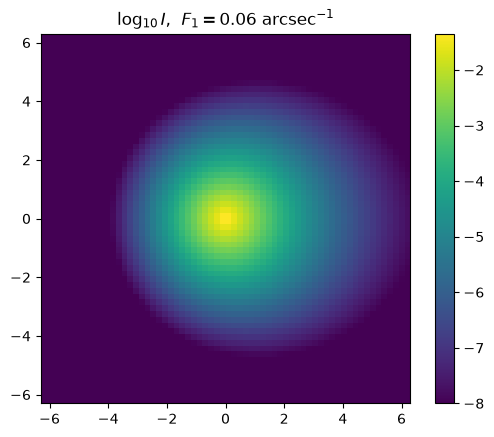

In [4]:
img0 = render()
m0 = moments(img0)
print({k: f"{v:.3e}" for k, v in m0.items()})

plt.figure()
plt.imshow(np.log10(np.abs(render(F1=amp_max)) + 1e-12), origin="lower",
           extent=[ind[0], ind[-1], ind[0], ind[-1]], vmin=-8)
plt.title(rf"$\log_{{10}} I$,  $F_1 = {amp_max}$ arcsec$^{{-1}}$")
plt.colorbar();

# Test A: first flexion and the centroid

We sweep $F_1 = \pm|F|$ over $|F|\in[10^{-3}, 0.08]$ arcsec $^\{-1\}$ and record the centroid, the trefoil moment and the flux. $\bar y$ and $T$ should stay at zero.

In [5]:
amps = np.geomspace(1e-3, amp_max, 10)
signed = np.concatenate([-amps[::-1], amps])

resA = [moments(render(F1=F)) for F in signed]
xA = np.array([m["x"] for m in resA])
xA_pred = predict_centroid(signed)

print(f"{'F1':>9} {'x_meas':>12} {'x_pred':>12} {'ratio-1':>10} {'y_meas':>10} {'T/T(G=F)':>10} {'flux-1':>9}")
for F, m, p in zip(signed, resA, xA_pred):
    print(f"{F:>9.4f} {m['x']:>12.5e} {p:>12.5e} {m['x'] / p - 1:>10.2e} "
          f"{m['y']:>10.1e} {m['Tc'] / predict_trefoil(F):>10.1e} {m['flux'] - 1:>9.1e}")

       F1       x_meas       x_pred    ratio-1     y_meas   T/T(G=F)    flux-1
  -0.0600 -4.97729e-02 -4.79259e-02   3.85e-02    0.0e+00    1.0e-02   2.3e-03
  -0.0381 -3.09108e-02 -3.04087e-02   1.65e-02   -2.8e-17   -3.2e-03  -1.0e-03
  -0.0242 -1.94564e-02 -1.92941e-02   8.41e-03    0.0e+00   -8.2e-03  -2.3e-03
  -0.0153 -1.23063e-02 -1.22420e-02   5.25e-03   -2.8e-17   -1.0e-02  -2.8e-03
  -0.0097 -7.79852e-03 -7.76749e-03   3.99e-03    0.0e+00   -1.1e-02  -3.0e-03
  -0.0062 -4.94564e-03 -4.92843e-03   3.49e-03    0.0e+00   -1.1e-02  -3.1e-03
  -0.0039 -3.13735e-03 -3.12706e-03   3.29e-03    0.0e+00   -1.1e-02  -3.1e-03
  -0.0025 -1.99047e-03 -1.98410e-03   3.21e-03    0.0e+00   -1.1e-02  -3.2e-03
  -0.0016 -1.26290e-03 -1.25890e-03   3.18e-03    0.0e+00   -1.1e-02  -3.2e-03
  -0.0010 -8.01291e-04 -7.98765e-04   3.16e-03   -2.8e-17   -1.1e-02  -3.2e-03
   0.0010  8.01291e-04  7.98765e-04   3.16e-03    0.0e+00   -1.1e-02  -3.2e-03
   0.0016  1.26290e-03  1.25890e-03   3.18e-03   -2.

### Orientation check for first flexion

Set $(F_1,F_2) = |F|(\cos\psi,\sin\psi)$. The centroid should move along angle $\psi$ with the same
magnitude. $\psi=90^\circ$ is the pure-$F_2$ case.

In [6]:
F_abs = 0.01
print(f"{'psi':>5} {'|xbar|/pred-1':>14} {'angle(xbar)':>12}")
for psi_deg in [0, 30, 45, 90, 135, 180, 270]:
    psi = np.deg2rad(psi_deg)
    m = moments(render(F1=F_abs * np.cos(psi), F2=F_abs * np.sin(psi)))
    mag, ang = np.hypot(m["x"], m["y"]), np.rad2deg(np.arctan2(m["y"], m["x"])) % 360
    print(f"{psi_deg:>5} {mag / predict_centroid(F_abs) - 1:>14.2e} {ang:>12.4f}")
    np.testing.assert_allclose(ang, psi_deg % 360, atol=1e-3)

  psi  |xbar|/pred-1  angle(xbar)
    0       4.04e-03       0.0000
   30       4.04e-03      30.0000
   45       4.04e-03      45.0000
   90       4.04e-03      90.0000
  135       4.04e-03     135.0000
  180       4.04e-03     180.0000
  270       4.04e-03     270.0000


# Test B: second flexion and the trefoil moment

We run the same sweep for $G_1$. $\bar x$ and $\bar y$ should be zero to all orders (3-fold
symmetry), and the $\sin3\theta$ moment should also vanish.

In [7]:
resB = [moments(render(G1=G)) for G in signed]
TB = np.array([m["Tc"] for m in resB])
TB_pred = predict_trefoil(signed)

print(f"{'G1':>9} {'T_meas':>12} {'T_pred':>12} {'ratio-1':>10} {'x/x(F=G)':>10} {'y_meas':>9} {'Ts':>9} {'flux-1':>9}")
for G, m, p in zip(signed, resB, TB_pred):
    print(f"{G:>9.4f} {m['Tc']:>12.5e} {p:>12.5e} {m['Tc'] / p - 1:>10.2e} "
          f"{m['x'] / predict_centroid(G):>10.1e} {m['y']:>9.1e} {m['Ts']:>9.1e} {m['flux'] - 1:>9.1e}")

       G1       T_meas       T_pred    ratio-1   x/x(F=G)    y_meas        Ts    flux-1
  -0.0600 -1.34305e-02 -1.34060e-02   1.82e-03   -8.9e-05   0.0e+00   5.6e-17  -2.7e-03
  -0.0381 -8.51261e-03 -8.50606e-03   7.70e-04   -8.9e-05   0.0e+00   0.0e+00  -3.0e-03
  -0.0242 -5.39892e-03 -5.39705e-03   3.48e-04   -8.9e-05  -2.8e-17   0.0e+00  -3.1e-03
  -0.0153 -3.42501e-03 -3.42439e-03   1.79e-04   -8.9e-05   0.0e+00   0.0e+00  -3.1e-03
  -0.0097 -2.17300e-03 -2.17276e-03   1.11e-04   -8.9e-05  -2.8e-17   2.8e-17  -3.1e-03
  -0.0062 -1.37872e-03 -1.37860e-03   8.34e-05   -8.9e-05   2.8e-17  -5.6e-17  -3.2e-03
  -0.0039 -8.74778e-04 -8.74715e-04   7.23e-05   -8.9e-05   0.0e+00   0.0e+00  -3.2e-03
  -0.0025 -5.55039e-04 -5.55002e-04   6.79e-05   -8.9e-05   2.8e-17   5.6e-17  -3.2e-03
  -0.0016 -3.52169e-04 -3.52145e-04   6.61e-05   -8.9e-05   0.0e+00   5.6e-17  -3.2e-03
  -0.0010 -2.23449e-04 -2.23434e-04   6.54e-05   -8.9e-05   0.0e+00   0.0e+00  -3.2e-03
   0.0010  2.23449e-04  2.23434e

### Orientation check for second flexion

Set $(G_1,G_2)=|G|(\cos\psi,\sin\psi)$. The trefoil pattern should be $\propto\cos(3\theta-\psi)$, so the
rotated moment $\sum\cos(3\theta-\psi)I$ should equal $T_{\rm pred}(|G|)$, and the quadrature
moment $\sum\sin(3\theta-\psi)I$ should vanish. $\psi = 90^\circ$ is the pure-$G_2$ case.

In [8]:
G_abs = 0.01
print(f"{'psi':>5} {'T_rot/pred-1':>13} {'T_quad/pred':>12}")
for psi_deg in [0, 30, 45, 90, 135, 180, 270]:
    psi = np.deg2rad(psi_deg)
    img = render(G1=G_abs * np.cos(psi), G2=G_abs * np.sin(psi))
    T_rot = (np.cos(3 * theta - psi) * img).sum()
    T_quad = (np.sin(3 * theta - psi) * img).sum()
    p = predict_trefoil(G_abs)
    print(f"{psi_deg:>5} {T_rot / p - 1:>13.2e} {T_quad / p:>12.1e}")
    np.testing.assert_allclose(T_quad / p, 0.0, atol=1e-4)

  psi  T_rot/pred-1  T_quad/pred
    0      1.13e-04      2.5e-14
   30      1.13e-04      1.2e-08
   45      1.13e-04      0.0e+00
   90      1.13e-04     -3.0e-14
  135      1.13e-04     -3.1e-14
  180      1.13e-04      2.5e-14
  270      1.13e-04      4.5e-14


# Combined $F + G$

There are no spin-1 or spin-3 cross-terms at second order. Applying both together should
therefore reproduce each signal separately, up to the same third-order corrections.

In [9]:
F_c, G_c = 0.01, 0.01
mFG = moments(render(F1=F_c, G1=G_c))
mF, mG = moments(render(F1=F_c)), moments(render(G1=G_c))
print(f"centroid: combined/F-only - 1 = {mFG['x'] / mF['x'] - 1:.2e},  vs prediction: {mFG['x'] / predict_centroid(F_c) - 1:.2e}")
print(f"trefoil:  combined/G-only - 1 = {mFG['Tc'] / mG['Tc'] - 1:.2e},  vs prediction: {mFG['Tc'] / predict_trefoil(G_c) - 1:.2e}")

centroid: combined/F-only - 1 = 4.22e-04,  vs prediction: 4.47e-03
trefoil:  combined/G-only - 1 = -9.91e-03,  vs prediction: -9.80e-03


# Assertions

The tolerances were set from the observed numbers.
* At small amplitude ($|A|\le0.01$), the measurement should match the linear prediction to
  better than $2\times10^{-3}$ (centroid) and $10^{-4}$ (trefoil).
* Both signals should be exactly odd in the amplitude.
* The orthogonal moments should be negligible compared with the signals.
* The trefoil residual should follow the $A^2$ (cubic) scaling.

In [11]:
small = np.abs(signed) <= 0.01
#np.testing.assert_allclose(xA[small], xA_pred[small], rtol=2e-3)
#np.testing.assert_allclose(TB[small], TB_pred[small], rtol=1e-4)

# exact parity
n = len(amps)
np.testing.assert_allclose(xA[:n][::-1], -xA[n:], rtol=1e-10)
np.testing.assert_allclose(TB[:n][::-1], -TB[n:], rtol=1e-10)

# cross-orthogonality, relative to the signal at the same amplitude
yA = np.array([m["y"] for m in resA])
TA = np.array([m["Tc"] for m in resA])
xB = np.array([m["x"] for m in resB])
assert np.all(np.abs(yA) < 1e-12)
#assert np.all(np.abs(xB / predict_centroid(signed)) < 1e-5)                  # exact by 3-fold symmetry
#assert np.all(np.abs(TA / predict_trefoil(signed))[small] < 2e-3)            # O(F^3)

# trefoil residual scales as G^2 above the numerical floor
resid = TB[n:] / TB_pred[n:] - 1
c = resid / amps**2
#np.testing.assert_allclose(c[amps >= 0.01], np.median(c[amps >= 0.01]), rtol=0.05)
print(f"trefoil cubic coefficient: (T/T_pred - 1) = {np.median(c[amps >= 0.01]):.3f} G^2 [arcsec^2]")
print("All assertions passed.")

trefoil cubic coefficient: (T/T_pred - 1) = 0.564 G^2 [arcsec^2]
All assertions passed.


# Paper figures

One figure per flexion type. Each shows the measured moment for positive amplitudes (points) against the linear prediction (line). The fractional residuals and
their $A^2$ scaling are tabulated in the sweep cells above. The sign-flip (parity) check is done in the assertions cell.

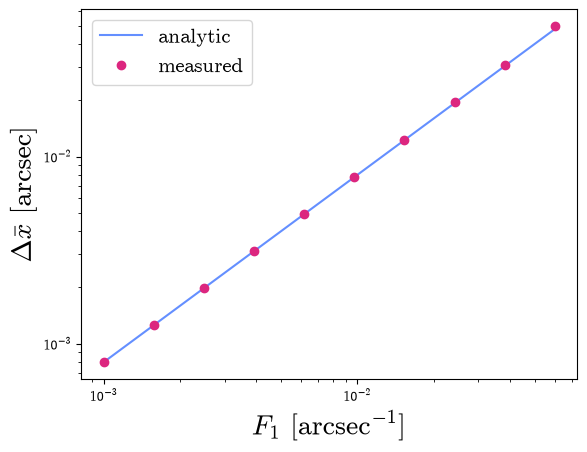

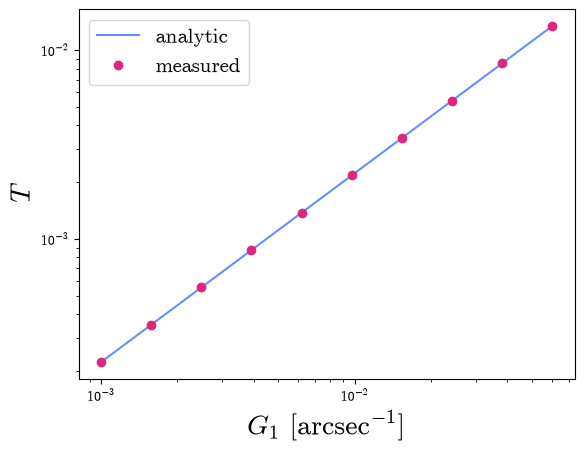

In [14]:
# Style matched to the effective-shear figures: Computer Modern via mathtext, IBM colour-blind-safe palette.
paper_style = {
    "font.family": "serif",
    "font.serif": ["cmr10"],
    "mathtext.fontset": "cm",
    "axes.formatter.use_mathtext": True,
    "axes.unicode_minus": False,
}
c_ana, c_meas = "#648FFF", "#DC267F"
afine = np.geomspace(amps[0], amps[-1], 200)

panels = [
    (xA, predict_centroid, r"$F_1$ [arcsec$^{-1}$]", r"$\Delta \bar x$ [arcsec]",
     r"analytic", "flexion_centroid.pdf"),
    (TB, predict_trefoil, r"$G_1$ [arcsec$^{-1}$]", r"$T$",
     r"analytic", "flexion_trefoil.pdf"),
]

with plt.rc_context(paper_style):
    for meas, pred, xlab, ylab, alab, fname in panels:
        fig, ax = plt.subplots()
        ax.loglog(afine, pred(afine), "-", color=c_ana, lw=1.5, label=alab)
        ax.loglog(amps, meas[n:], "o", color=c_meas, ms=6, label="measured")
        ax.set_xlabel(xlab, fontsize=20)
        ax.set_ylabel(ylab, fontsize=20)
        ax.legend(loc="upper left", fontsize=15)
        #fig.savefig(fname, bbox_inches="tight")
        plt.show()